In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
np.random.seed(42)

n = 200

area = np.random.normal(150, 40, n)
rooms = area / 25 + np.random.normal(0, 0.8, n)
age = np.random.uniform(0, 30, n)
distance = np.random.uniform(1, 20, n)
noise = np.random.normal(0, 15000, n)

price = (
    30000 + 2500 * area + 10000 * rooms - 1200 * age - 1800 * distance + noise
)

df = pd.DataFrame({
    "Area": area,
    "Rooms": rooms,
    "Age": age,
    "Distance": distance,
    "Price": price
})

In [3]:
print(df.head())

         Area     Rooms        Age   Distance          Price
0  169.868566  7.080973  12.444585   3.655675  508584.449801
1  144.469428  6.227405   8.202212  16.110079  388954.294730
2  175.907542  7.902743   1.691265   4.830919  517848.326808
3  210.921194  9.279889  25.941671   4.109463  622723.802379
4  140.633865  4.523219  24.387030   4.121050  392697.508542


In [4]:
X = df.drop(columns="Price")
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=10),
    "Lasso": Lasso(alpha=1000, max_iter=10000),
    "Elastic Net": ElasticNet(
        alpha=1000,
        l1_ratio=0.5,
        max_iter=10000
    )
}

In [6]:
results = []
coefficients = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    coef = pipeline.named_steps["model"].coef_
    coefficients[name] = coef

    results.append({
        "Model": name,
        "RMSE": rmse,
        "R2": r2
    })

results_df = pd.DataFrame(results)

print("\nModel Performance:")
print(results_df.round(3).to_string(index=False))


Model Performance:
            Model       RMSE     R2
Linear Regression  14344.137  0.981
            Ridge  18802.640  0.968
            Lasso  14929.044  0.980
      Elastic Net 104900.451 -0.005


In [7]:
coef_df = pd.DataFrame(
    coefficients,
    index=X.columns
)

print("\nModel Coefficients:")
print(coef_df.round(2))


Model Coefficients:
          Linear Regression     Ridge     Lasso  Elastic Net
Area               90046.62  74276.65  89728.25       214.69
Rooms              18867.14  31162.90  18232.22       200.40
Age                -8720.57  -8083.19  -7685.03       -14.58
Distance          -10738.03 -10850.75  -9784.98       -42.87


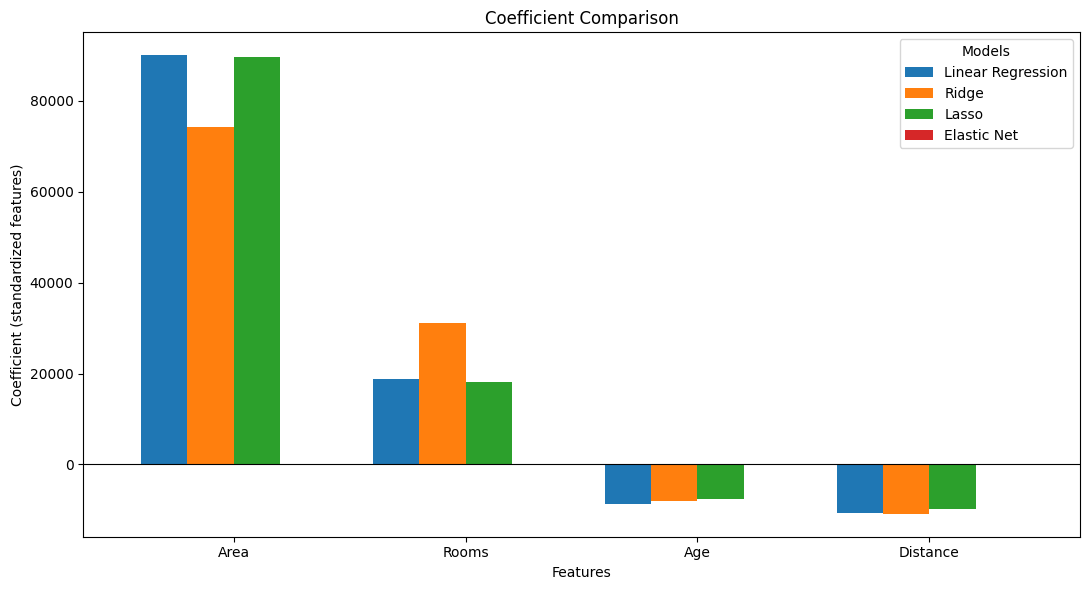

In [10]:
coef_df.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

plt.title("Coefficient Comparison")
plt.xlabel("Features")
plt.ylabel("Coefficient (standardized features)")
plt.axhline(y=0, color="black", linewidth=0.8)
plt.xticks(rotation=0)
plt.legend(title="Models")
plt.tight_layout()
plt.show()